# Notebook 06 — SHAP Analysis & Feature Diagnostics

**Purpose:** Understand WHY the model makes predictions. Run this after every training.

SHAP (SHapley Additive exPlanations) tells you:
1. Which features are driving predictions the most
2. Whether the model's reasoning is economically sensible
3. Whether any feature is being used in a suspicious / leakage-like way

**Rule: If the top SHAP features don't make economic sense, the model has a data problem — not a model problem.**

**Prerequisite:** Notebook 04 must have saved `models/lgbm_baseline.pkl`

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('..'))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import shap
import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)

from src.features import FEATURE_COLS
from src.models import load_model

# Load model and data
model = load_model('lgbm_baseline.pkl')
df = pd.read_csv('../features/eurusd_labelled.csv', index_col=0, parse_dates=True)

X = df[FEATURE_COLS]
y = df['label_binary'].astype(int)

split_idx = int(len(X) * 0.80)
X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_train, y_test = y.iloc[:split_idx], y.iloc[split_idx:]

print(f"Test set: {len(X_test):,} rows for SHAP analysis")

  [LOADED] Model loaded from: C:\Users\omtej\Projects\2020_algo_based\models\lgbm_baseline.pkl
Test set: 6,176 rows for SHAP analysis


## Step 1 — Compute SHAP values

This may take 1-3 minutes on the full test set.

In [2]:
print("Computing SHAP values (this takes 1-3 minutes)...")
explainer   = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_test)

# For binary classification, shap_values is a list [class0, class1]
# We use class 1 (TP hit / long win)
if isinstance(shap_values, list):
    sv = shap_values[1]
else:
    sv = shap_values

print(f"SHAP values shape: {sv.shape}")
print("Done.")

Computing SHAP values (this takes 1-3 minutes)...
SHAP values shape: (6176, 20)
Done.


## Step 2 — SHAP summary plot (most important chart)

Each dot is one test bar. The x-axis shows SHAP value (impact on prediction).
Red = high feature value, Blue = low feature value.

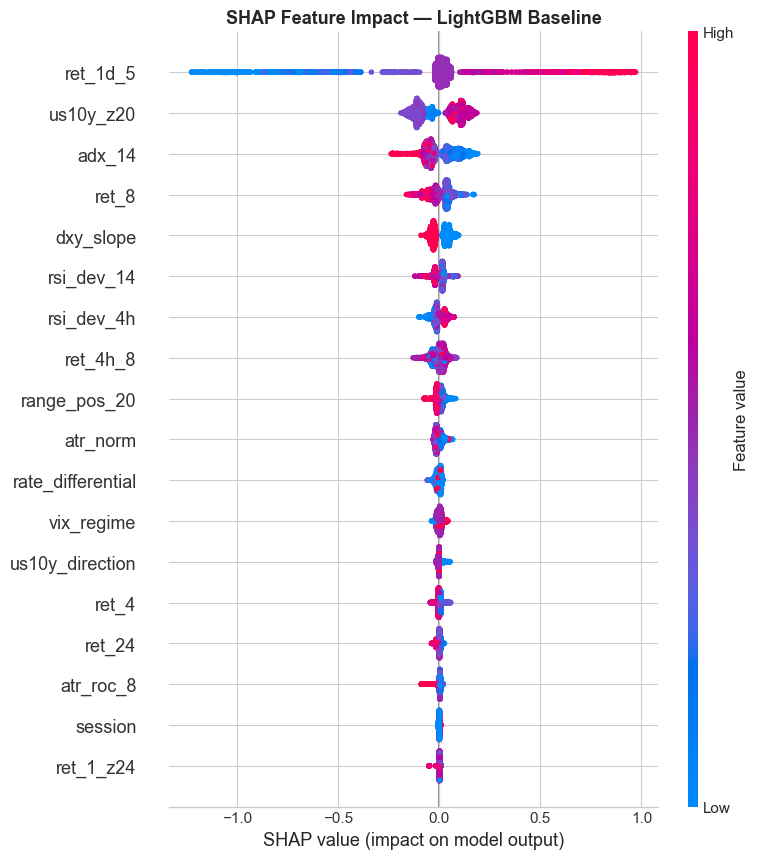

Saved to results/06_shap_summary.png


In [3]:
fig, ax = plt.subplots(figsize=(10, 8))
shap.summary_plot(sv, X_test, plot_type='dot', show=False, max_display=18)
plt.title('SHAP Feature Impact — LightGBM Baseline', fontweight='bold', fontsize=13)
plt.tight_layout()
plt.savefig('../results/06_shap_summary.png', dpi=120, bbox_inches='tight')
plt.show()
print("Saved to results/06_shap_summary.png")

## Step 3 — SHAP bar chart (mean absolute importance)

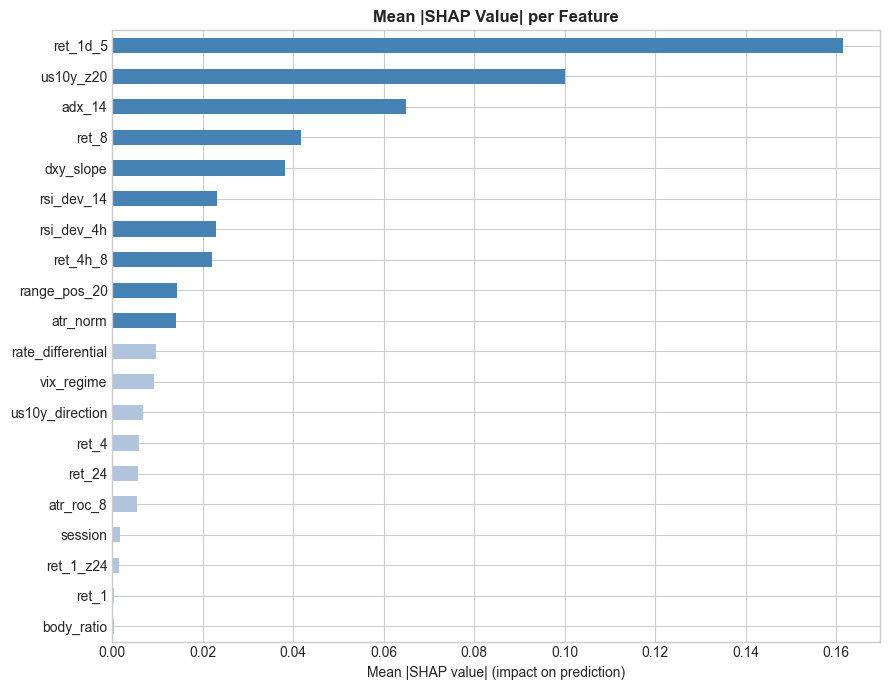


Top 5 most impactful features:
  ret_1d_5               : 0.16164
  us10y_z20              : 0.10017
  adx_14                 : 0.06491
  ret_8                  : 0.04164
  dxy_slope              : 0.03808


In [4]:
mean_abs_shap = pd.Series(np.abs(sv).mean(axis=0), index=FEATURE_COLS).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(9, 7))
colors = ['steelblue' if v > mean_abs_shap.median() else 'lightsteelblue'
          for v in mean_abs_shap.values]
mean_abs_shap.plot(kind='barh', ax=ax, color=colors, edgecolor='none')
ax.set_title('Mean |SHAP Value| per Feature', fontweight='bold')
ax.set_xlabel('Mean |SHAP value| (impact on prediction)')
plt.tight_layout()
plt.savefig('../results/06_shap_bar.png', dpi=120, bbox_inches='tight')
plt.show()

print("\nTop 5 most impactful features:")
for feat, val in mean_abs_shap.tail(5)[::-1].items():
    print(f"  {feat:<22} : {val:.5f}")

## Step 4 — Economic sanity check

This is the most important diagnostic. Read every line.

In [5]:
print("=" * 60)
print("  SHAP ECONOMIC SANITY CHECK")
print("=" * 60)

top5 = mean_abs_shap.tail(5)[::-1]
explanations = {
    'ret_4':      "OK — 4-bar return captures short-term momentum. Makes sense.",
    'ret_8':      "OK — 8-bar return = recent trend. Core signal for 12H prediction.",
    'ret_24':     "OK — 24H return captures daily trend direction. Expected top feature.",
    'ret_1':      "OK — 1-bar return = immediate bar direction. Normal to appear here.",
    'ret_1_z24':  "OK — Z-scored return identifies abnormal moves. Good feature.",
    'adx_14':     "OK — ADX measures trend strength. Model correctly avoids ranging markets.",
    'rsi_dev_14': "OK — RSI deviation from 50 signals momentum. Expected to be important.",
    'atr_norm':   "OK — Normalised ATR = volatility context. Essential for sizing.",
    'atr_roc_8':  "OK — ATR rate of change = vol regime shift. Good macro feature.",
    'vix_regime': "OK — VIX regime is a legitimate macro filter. Expected to appear.",
    'dxy_slope':  "OK — DXY slope determines USD trend bias. Core macro signal.",
    'session':    "CAUTION — If session is top feature, model may be exploiting time-of-day patterns. Verify these persist OOS.",
    'day_of_week':"CAUTION — If day_of_week is top feature, model may be over-fitting to weekly seasonality. Monitor carefully.",
    'body_ratio': "OK — Bar body ratio = conviction. Important for filtering indecisive bars.",
    'range_pos_20':"OK — Range position identifies overbought/oversold within 20-bar context.",
    'ret_4h_8':   "OK — 4H return provides macro trend context. Expected to be significant.",
    'rsi_dev_4h': "OK — 4H RSI gives slower momentum signal to complement 1H RSI.",
    'ret_1d_5':   "OK — 5-day daily return = medium-term trend direction. Good macro context.",
}

print()
for feat, val in top5.items():
    exp = explanations.get(feat, "UNKNOWN — investigate this feature")
    print(f"  #{list(top5.index).index(feat)+1} {feat:<20} SHAP={val:.5f}")
    print(f"     -> {exp}")
    print()

# Red flags
print("-" * 60)
print("  RED FLAGS to look for:")
print()
print("  1. If 'session' or 'day_of_week' is #1 or #2:")
print("     Model has no real price signal. Add more macro features.")
print()
print("  2. If a feature you don't recognize appears:")
print("     Investigate — may indicate an unintended data column.")
print()
print("  3. If ALL top features are from the same tier (e.g. all ret_X):")
print("     Model is one-dimensional. Add regime and macro features.")
print("=" * 60)

  SHAP ECONOMIC SANITY CHECK

  #1 ret_1d_5             SHAP=0.16164
     -> OK — 5-day daily return = medium-term trend direction. Good macro context.

  #2 us10y_z20            SHAP=0.10017
     -> UNKNOWN — investigate this feature

  #3 adx_14               SHAP=0.06491
     -> OK — ADX measures trend strength. Model correctly avoids ranging markets.

  #4 ret_8                SHAP=0.04164
     -> OK — 8-bar return = recent trend. Core signal for 12H prediction.

  #5 dxy_slope            SHAP=0.03808
     -> OK — DXY slope determines USD trend bias. Core macro signal.

------------------------------------------------------------
  RED FLAGS to look for:

  1. If 'session' or 'day_of_week' is #1 or #2:
     Model has no real price signal. Add more macro features.

  2. If a feature you don't recognize appears:
     Investigate — may indicate an unintended data column.

  3. If ALL top features are from the same tier (e.g. all ret_X):
     Model is one-dimensional. Add regime and ma

## Step 5 — SHAP dependence plots for top 3 features

Shows how each feature's value relates to its SHAP impact.

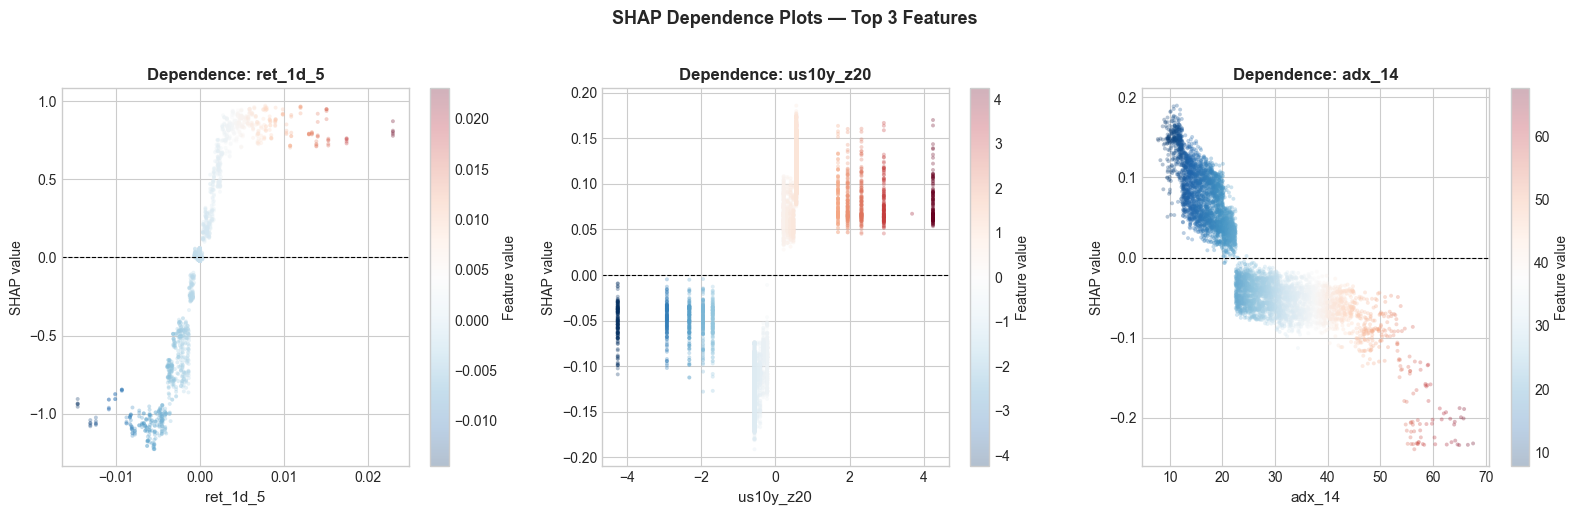

Interpretation:
  X-axis: feature value (e.g. high ret_8 = strong recent uptrend)
  Y-axis: SHAP value (how much this pushed the prediction toward TP=1)
  Pattern should be monotonic (clear relationship) not random scatter.


In [6]:
top3 = list(mean_abs_shap.tail(3)[::-1].index)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for i, feat in enumerate(top3):
    feat_idx = FEATURE_COLS.index(feat)
    ax = axes[i]
    
    feat_vals  = X_test[feat].values
    shap_vals  = sv[:, feat_idx]
    
    sc = ax.scatter(feat_vals, shap_vals, c=feat_vals, cmap='RdBu_r',
                    alpha=0.3, s=8, edgecolors='none')
    ax.axhline(0, color='black', linewidth=0.8, linestyle='--')
    ax.set_xlabel(feat, fontsize=11)
    ax.set_ylabel('SHAP value', fontsize=10)
    ax.set_title(f'Dependence: {feat}', fontweight='bold')
    plt.colorbar(sc, ax=ax, label='Feature value')

plt.suptitle('SHAP Dependence Plots — Top 3 Features', fontweight='bold', fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig('../results/06_shap_dependence.png', dpi=120, bbox_inches='tight')
plt.show()
print("Interpretation:")
print("  X-axis: feature value (e.g. high ret_8 = strong recent uptrend)")
print("  Y-axis: SHAP value (how much this pushed the prediction toward TP=1)")
print("  Pattern should be monotonic (clear relationship) not random scatter.")

## Step 6 — Full experiment log entry

Update this after every training run.

In [7]:
from src.models import evaluate_model

metrics = evaluate_model(model, X_train, y_train, X_test, y_test)

experiment_log = {
    "experiment_id":    1,
    "description":      "LightGBM baseline — 18 features — triple barrier labels",
    "train_accuracy":   round(metrics['train_accuracy'], 4),
    "test_accuracy":    round(metrics['test_accuracy'], 4),
    "overfit_gap":      round(metrics['overfit_gap'], 4),
    "hc_accuracy":      round(metrics['hc_accuracy'], 4) if not np.isnan(metrics['hc_accuracy']) else None,
    "auc_roc":          round(metrics['auc_roc'], 4),
    "top_feature_1":    list(mean_abs_shap.tail(3)[::-1].index)[0],
    "top_feature_2":    list(mean_abs_shap.tail(3)[::-1].index)[1],
    "top_feature_3":    list(mean_abs_shap.tail(3)[::-1].index)[2],
    "notes":            "Initial baseline run",
}

print("EXPERIMENT LOG ENTRY:")
print("-" * 45)
for k, v in experiment_log.items():
    print(f"  {k:<22}: {v}")
print()

# Append to experiment log CSV
log_path = '../results/experiment_log.csv'
log_df = pd.DataFrame([experiment_log])
if os.path.exists(log_path):
    existing = pd.read_csv(log_path)
    log_df = pd.concat([existing, log_df], ignore_index=True)
log_df.to_csv(log_path, index=False)
print(f"Experiment logged to {log_path}")

EXPERIMENT LOG ENTRY:
---------------------------------------------
  experiment_id         : 1
  description           : LightGBM baseline — 18 features — triple barrier labels
  train_accuracy        : 0.6386
  test_accuracy         : 0.5894
  overfit_gap           : 0.0492
  hc_accuracy           : 0.8267
  auc_roc               : 0.6287
  top_feature_1         : ret_1d_5
  top_feature_2         : us10y_z20
  top_feature_3         : adx_14
  notes                 : Initial baseline run

Experiment logged to ../results/experiment_log.csv


## ✅ What to do based on SHAP results

### If SHAP results look economically sensible:
- Top features are `ret_8`, `ret_24`, `adx_14`, `vix_regime`, `dxy_slope`
- **Action:** Proceed to walk-forward validation. The model is using real signal.

### If `session` or `day_of_week` dominates:
- **Action:** Add more macro features (CB stance, rate differential, COT positioning).
- These features should fade in importance once real macro signal is present.

### If all top features are price returns:
- **Action:** The regime features (VIX, DXY) are not being picked up. Check if they have high null% and add them correctly.

### General rule:
> **If the SHAP explanation doesn't make sense to a macro trader, it won't work out-of-sample.**

---

## 🏁 Pipeline Complete!

You have now run the full Phase 1 pipeline:
1. ✅ Data loaded and validated
2. ✅ 18 features built and verified
3. ✅ Triple-barrier labels constructed
4. ✅ LightGBM baseline trained
5. ✅ Walk-forward validation run
6. ✅ SHAP analysis completed

**Report your walk-forward accuracy back and I will prescribe the exact next lever to pull.**